# 05 注意力机制、QKV与Seq2Seq基础

本篇对应 **day05**，保存在「黑马程序员 → AI大模型开发 → 07-NLP自然语言处理」。承接04的循环网络与分类损失，本篇学习怎样让模型根据当前查询，动态汇总一段序列的信息，再把注意力接入Encoder–Decoder。

资料：[2026最新版NLP自然语言处理](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。已核对 `03-视频/day05` 的 **14节文件名**，在线阅读《06-注意力机制介绍》全部39页，并检查公式和实现页的显示。视频未逐段转录，未取得课程原代码和本地PDF。本篇代码、微型数据和7幅教学图均独立编写，不把随机前向或小实验当作课件成绩。

沿用前篇格式：**全部为Markdown单元，Python代码块按顺序复制到代码单元即可运行；所有图片直接嵌入Notebook附件。** 本日重点是注意力计算与Seq2Seq接口，不提前展开完整英译法数据集与翻译训练。

| day05视频 | 主题 | 本篇学习目标 |
| --- | --- | --- |
| 01–03 | 概念、QKV、实现步骤 | 分清分数、权重、上下文表示 |
| 04–08 | Seq2Seq、Encoder–Decoder扩展 | 理解固定上下文与动态上下文 |
| 09 | 软/硬/自注意力 | 按选择方式和输入来源分别理解 |
| 10–11 | 计算规则、bmm | 核对公式与每一步shape |
| 12–14 | 实现、测试、参数解释 | 读懂课件固定位置模块，完成可靠的批量实现 |

本篇主线：`Q与K打分 → mask → 沿源位置Softmax → 权重乘V → 上下文 → 融合与任务输出`。

## 1. 环境与运行约定

代码只依赖Python、NumPy和PyTorch；不联网，不需要课程语料。所有图已经内嵌，阅读无需绘图库。先执行本节，再按顺序执行后续Python代码块。

```bash
python -m pip install numpy torch
```

```python
import math
import platform
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

SEED = 2026
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cpu")
print("Python", platform.python_version(), "NumPy", np.__version__)
print("PyTorch", torch.__version__, "device", DEVICE)
```

本篇默认CPU。确定性设置方便复查教学数值，不能保证不同版本、设备的末位浮点数完全相同。代码不保存外部数据、图片或模型文件。

## 2. 注意力：按查询动态汇总信息

注意力把若干候选内容加权汇总：当前查询更相关的位置权重通常更大。视觉关注的比喻帮助入门，但神经网络实现是张量运算，并不等同于人的意识或理解过程。

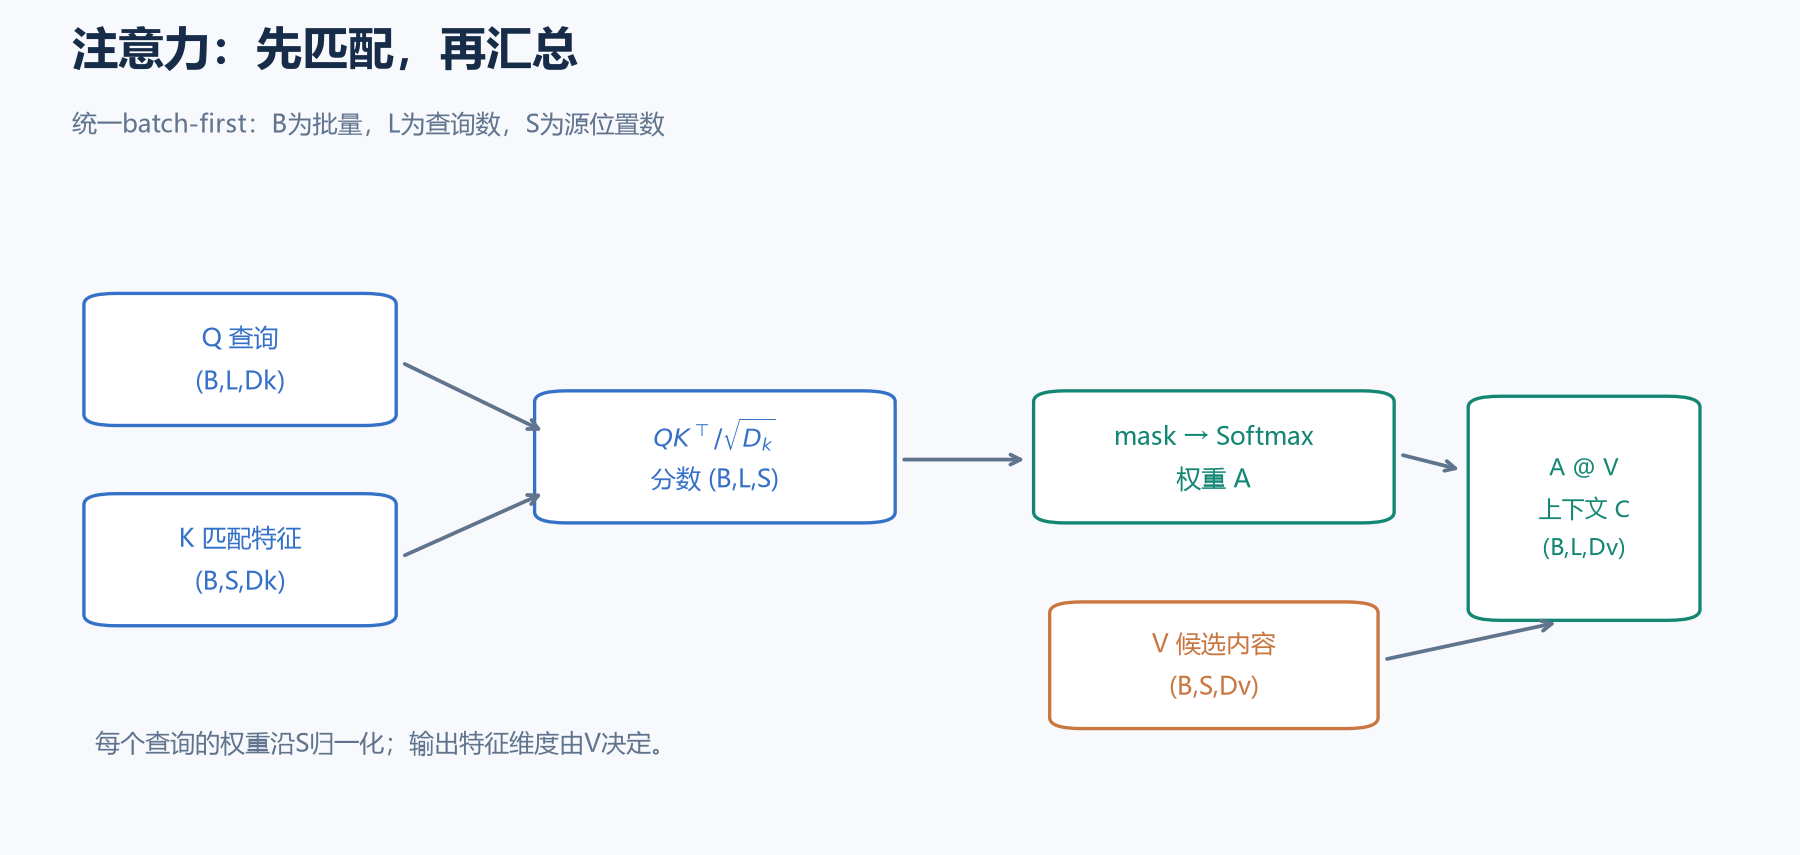

RNN按时间递推，传统无注意力Seq2Seq常把源序列压成固定向量，长序列信息容易形成瓶颈。注意力让解码器每一步重新读取编码器各位置表示，而不是只依赖一个固定摘要。

需要区分：**加入注意力不会自动把整个RNN变成并行网络**。某一步对全部源位置的打分可并行，但RNN编码与自回归生成仍有时间依赖。全序列自注意力通常涉及两两位置关系，常规实现的分数矩阵占用随长度平方增长，并非免费处理无限长文本。

## 3. Q、K、V各自做什么

| 张量 | 含义 | 在计算中的用途 |
| --- | --- | --- |
| Query，Q | 当前要查询什么 | 与候选键比较，决定读取偏好 |
| Key，K | 每个候选的匹配特征 | 参与打分，通常每个源位置一个键向量 |
| Value，V | 每个候选携带的内容 | 被注意力权重加权汇总 |

档案柜类比：Q是查找需求，K是文件标签，V是文件内容。但网络里的K通常是**可学习的特征向量**，不只是整数位置或字典索引；Q也不是一定能读懂的一句自然语言问题。

Q/K/V可以由embedding、RNN隐藏状态或线性投影得到。它们的来源取决于具体模型。K与V共享源位置数量，却可以有不同特征维度；输出上下文的特征维度跟随V，不必等于Q。

## 4. 先定形状，再看公式

本篇统一使用batch-first三维张量：

| 符号 | 含义 | shape |
| --- | --- | --- |
| Q | L个查询 | `(B,L,Dk)` |
| K | S个源位置的键 | `(B,S,Dk)` |
| V | S个源位置的值 | `(B,S,Dv)` |
| scores | 查询与源位置的匹配分数 | `(B,L,S)` |
| A | 归一化注意力权重 | `(B,L,S)` |
| context | 每个查询的内容汇总 | `(B,L,Dv)` |

其中B是batch大小，L是查询个数，S是源位置数。**Dk与S不是同一个量**；Softmax沿S轴，即`dim=-1`。K与V的第j行必须对应同一源位置。

缩放点积注意力：

$$E=\frac{QK^\top}{\sqrt{D_k}},\qquad A=\operatorname{softmax}_{S}(E+M),\qquad C=AV.$$

M在允许位置为0，禁止位置为$-\infty$。实现时可用布尔mask与`masked_fill`，无须手工构造完整加法矩阵。

context是读取V得到的表示。要把它与原查询融合，可拼接后线性投影、残差或其他结构；“更强大的Q”只是课件的直观说法，**随机权重不保证提升任务效果**。

## 5. torch.bmm：每个batch做一次矩阵乘法

`bmm`只处理两个三维张量，batch大小要相同，矩阵内维要匹配；它不自动广播batch维。若`(B,N,M) @ (B,M,P)`，结果是`(B,N,P)`。

```python
a = torch.arange(12, dtype=torch.float64).reshape(2, 2, 3) / 10
b = torch.arange(24, dtype=torch.float64).reshape(2, 3, 4) / 7
batched = torch.bmm(a, b)
looped = torch.stack([a[i] @ b[i] for i in range(len(a))])
torch.testing.assert_close(batched, looped)
torch.testing.assert_close(batched, torch.matmul(a, b))
assert batched.shape == (2, 2, 4)
try:
    torch.bmm(a, b[:1])
except RuntimeError:
    print("bmm已拒绝batch大小不同的输入")
else:
    raise AssertionError("bmm不应广播batch维")
print("结果shape:", tuple(batched.shape))
```

注意力中两次bmm：`Q @ K.transpose(1,2)`得到分数；`A @ V`得到上下文。`torch.matmul`还能处理更一般的维数与广播；本篇使用bmm让batch契约清楚可见。

## 6. 手算：两个查询读取三个候选

取`Dk=2`、`Dv=2`，两个查询分别偏向第一个、第二个特征：

$$Q=\begin{bmatrix}1&0\\0&1\end{bmatrix},\quad K=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix},\quad V=\begin{bmatrix}1&2\\3&4\\5&0\end{bmatrix}.$$

对第一个查询，分数是`[1,0,1]/sqrt(2)`，归一化权重约为`[0.4011,0.1978,0.4011]`。上下文是这三个V向量的加权和，约`[3.0000,1.5933]`。权重不是“选择一个位置”，而是同时混合多个位置。

```python
manual_q = torch.tensor([[[1., 0.], [0., 1.]]], dtype=torch.float64)
manual_k = torch.tensor([[[1., 0.], [0., 1.], [1., 1.]]], dtype=torch.float64)
manual_v = torch.tensor([[[1., 2.], [3., 4.], [5., 0.]]], dtype=torch.float64)
manual_scores = torch.bmm(manual_q, manual_k.transpose(1, 2)) / math.sqrt(2)
manual_weights = manual_scores.softmax(dim=-1)
manual_context = torch.bmm(manual_weights, manual_v)
np_scores = manual_q.numpy() @ manual_k.numpy().transpose(0, 2, 1) / np.sqrt(2)
np_shifted = np_scores - np_scores.max(axis=-1, keepdims=True)
np_weights = np.exp(np_shifted) / np.exp(np_shifted).sum(axis=-1, keepdims=True)
np_context = np_weights @ manual_v.numpy()
np.testing.assert_allclose(manual_weights.numpy(), np_weights, atol=1e-12)
np.testing.assert_allclose(manual_context.numpy(), np_context, atol=1e-12)
torch.testing.assert_close(manual_weights.sum(-1), torch.ones((1, 2), dtype=torch.float64))
assert torch.all(manual_weights >= 0)
for query in range(2):
    explicit = sum(manual_weights[0, query, j] * manual_v[0, j] for j in range(3))
    torch.testing.assert_close(explicit, manual_context[0, query])
print("分数:\n", manual_scores)
print("权重:\n", manual_weights)
print("上下文:\n", manual_context)
```

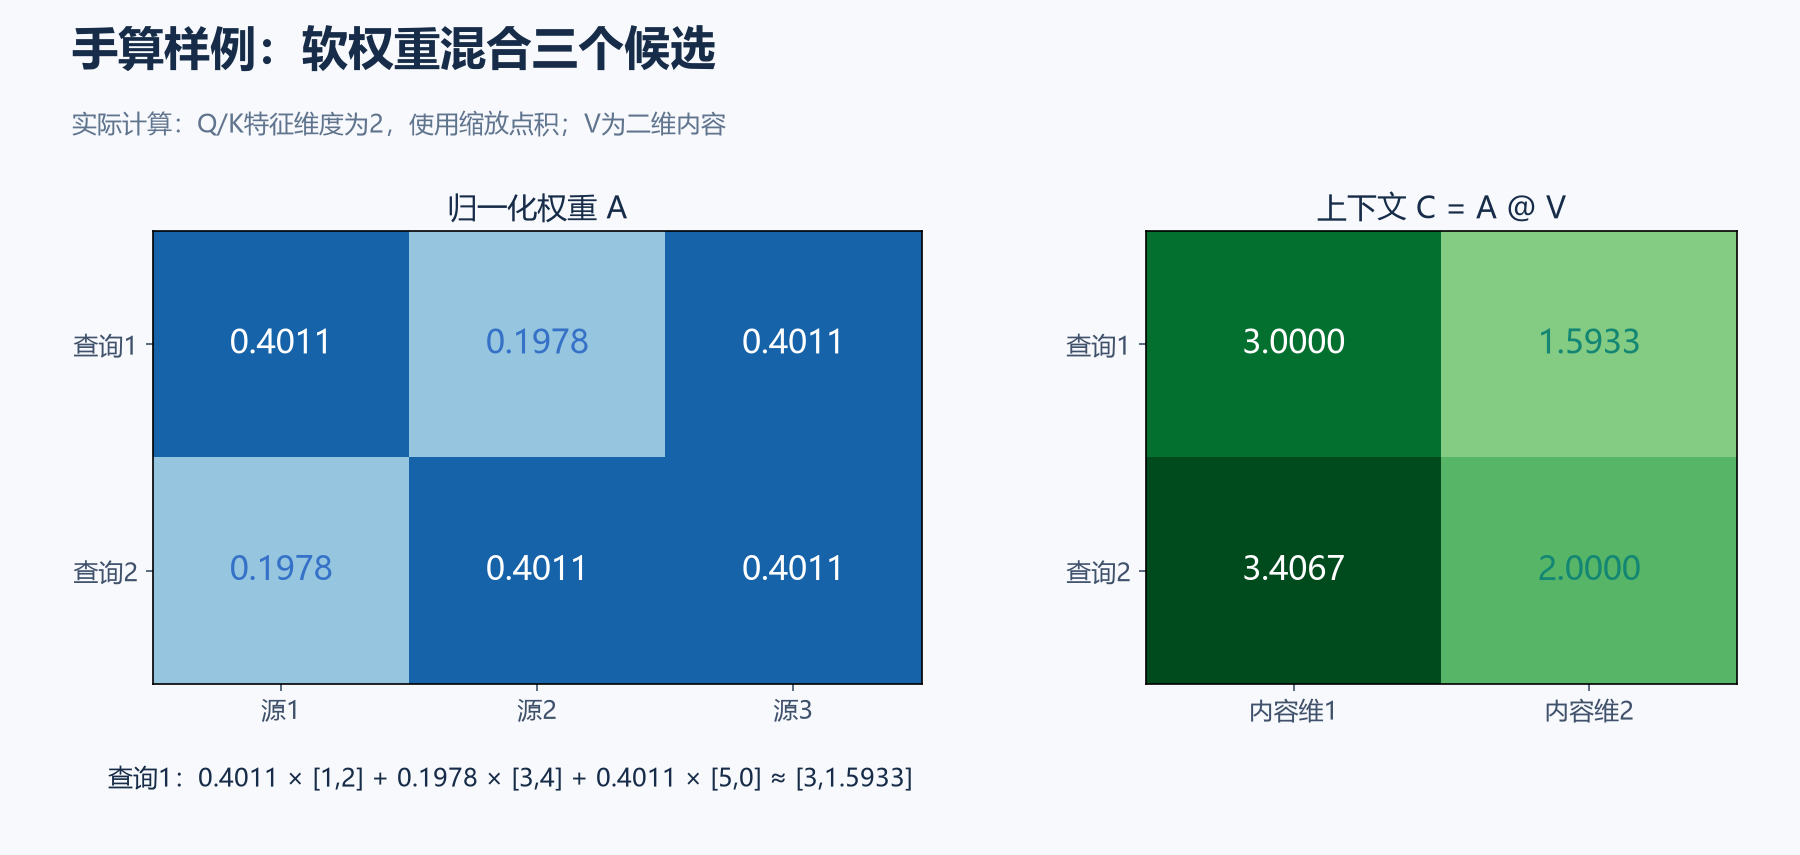

这组向量是自编数值样例，不表示真实句子的语义关系。注意力权重可用于观察模型行为，但不是对因果重要性或语言学解释的自动证明。

## 7. 为什么除以sqrt(Dk)

若Q和K各维近似独立、均值0、方差1，点积是Dk项乘积的和，其方差约为Dk。除以`sqrt(Dk)`后方差约为1，可以减轻维度增大时分数尺度变大、Softmax过度尖锐和梯度饱和的问题。

这是初始化尺度下的近似分析，不意味着真实特征一定独立，也不是保证“所有梯度不消失/不爆炸”的通用解法。Softmax的数值稳定实现与分数缩放解决的也不是完全同一件事。

```python
torch.manual_seed(SEED)
scale_observations = {}
for dim in (4, 64, 256):
    q_sample = torch.randn(10000, dim, dtype=torch.float64)
    k_sample = torch.randn(10000, dim, dtype=torch.float64)
    dot = (q_sample * k_sample).sum(-1)
    scaled = dot / math.sqrt(dim)
    scale_observations[dim] = {"raw_std": dot.std().item(), "scaled_std": scaled.std().item()}
    assert 0.95 < scaled.std().item() < 1.05
print("维度与分数标准差:", scale_observations)
```

课件示例出现`torch.sqrt(query.shape[-1])`，shape取出来是Python整数，不能直接传给要求Tensor的`torch.sqrt`。本篇统一用`math.sqrt(query.shape[-1])`；分母是Q/K的特征维度Dk，不是源长度S或V维度Dv。

## 8. mask：在Softmax之前排除无效位置

PAD即使对应零向量，Softmax仍可能给它正权重；V即使为零，PAD也会分走其他位置的概率质量。应在归一化**之前**把禁止位置分数置为`-inf`。

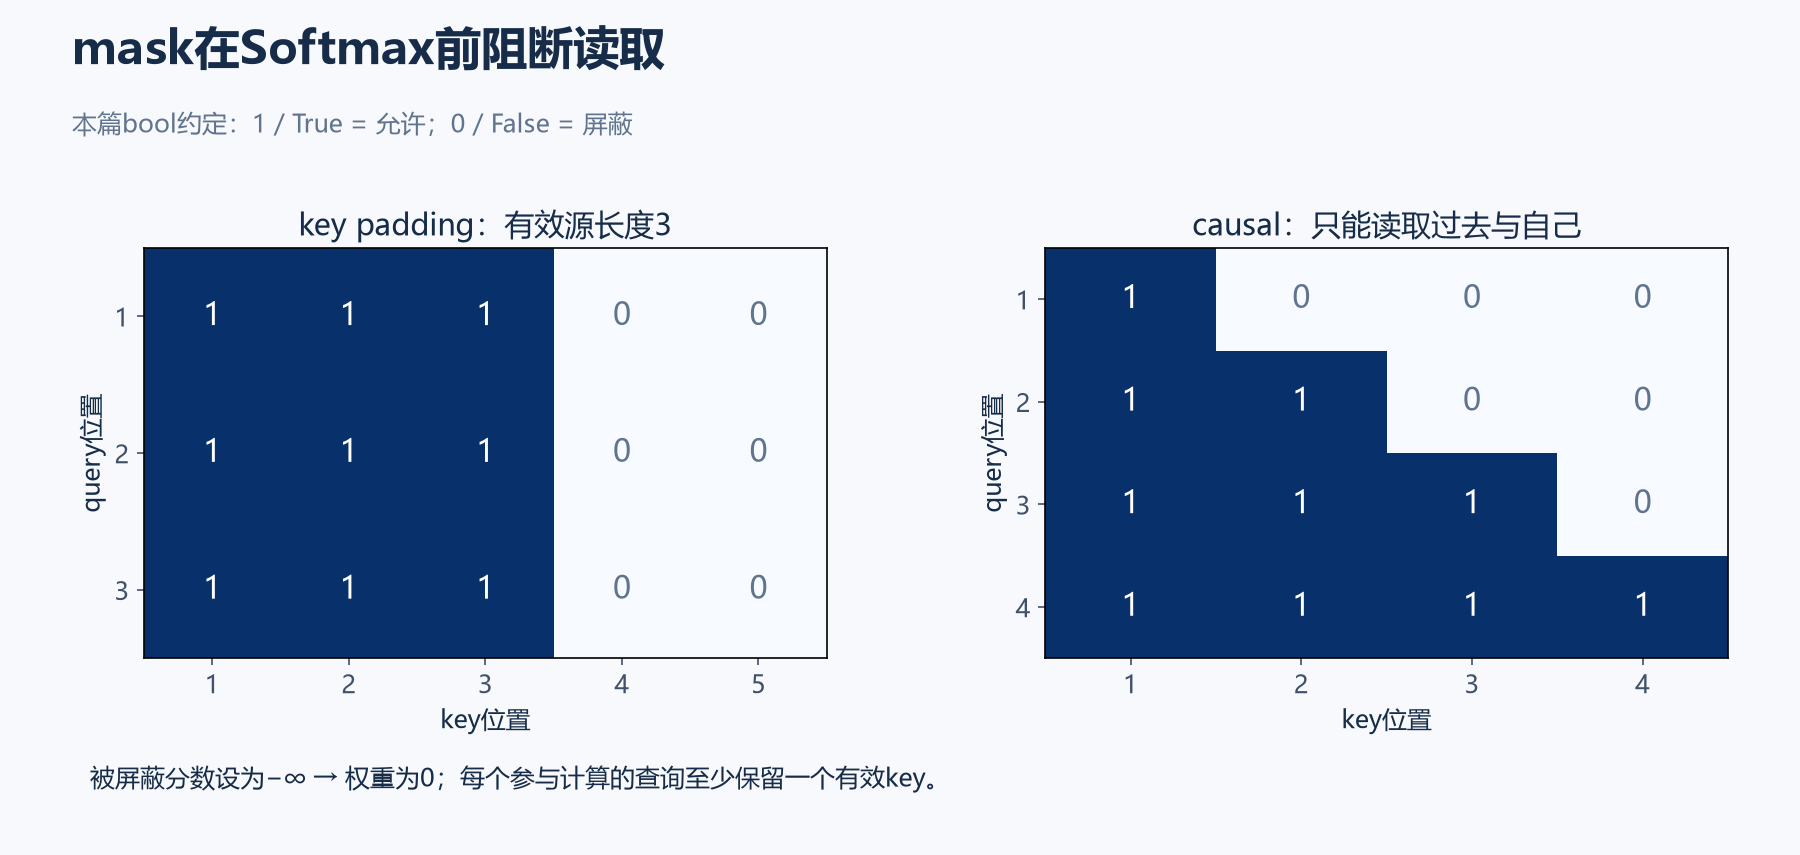

本篇统一约定 **`allowed=True`表示可以读取**。mask的shape与scores相同`(B,L,S)`。每个查询至少保留一个可读位置；全屏蔽一行时Softmax没有合法概率分布，本篇直接报错，不偷偷用均匀权重或NaN继续计算。

```python
def masked_softmax(scores, allowed=None):
    if scores.ndim != 3 or not scores.is_floating_point() or not torch.isfinite(scores).all():
        raise ValueError("scores必须为有限的三维浮点张量")
    if allowed is not None:
        if allowed.dtype != torch.bool or allowed.shape != scores.shape or allowed.device != scores.device:
            raise ValueError("allowed必须与scores同shape、同设备，且为bool")
        if not allowed.any(dim=-1).all():
            raise ValueError("存在没有任何可读位置的查询")
        scores = scores.masked_fill(~allowed, -torch.inf)
    return scores.softmax(dim=-1)

check_scores = torch.tensor([[[0., 1., 100.]]], dtype=torch.float64)
check_allowed = torch.tensor([[[True, True, False]]])
check_weights = masked_softmax(check_scores, check_allowed)
assert check_weights[0, 0, 2].item() == 0.0
torch.testing.assert_close(check_weights[0, 0, :2], torch.tensor([0., 1.], dtype=torch.float64).softmax(-1))
torch.testing.assert_close(check_weights.sum(-1), torch.ones((1, 1), dtype=torch.float64))
try:
    masked_softmax(check_scores, torch.zeros_like(check_allowed))
except ValueError:
    print("已拒绝全屏蔽行")
else:
    raise AssertionError("全屏蔽行必须明确处理")
```

key padding mask排除源端PAD；causal mask排除未来位置。查询端PAD则应在任务损失或输出使用时单独忽略，不能以为屏蔽key就自动排除了PAD查询。

## 9. 可检查的缩放点积注意力函数

本函数支持`B>1`、`L>1`、`Dk!=Dv`，返回上下文和权重。检查错误shape、设备、dtype、空维度和非有限输入，避免错误广播或索引被掩盖。

```python
def scaled_dot_attention(q, k, v, allowed=None):
    if any(t.ndim != 3 for t in (q, k, v)):
        raise ValueError("QKV都必须是三维张量")
    if any(size <= 0 for t in (q, k, v) for size in t.shape):
        raise ValueError("QKV维度必须非空")
    if q.shape[0] != k.shape[0] or k.shape[:2] != v.shape[:2] or q.shape[-1] != k.shape[-1]:
        raise ValueError("batch、源位置或Q/K特征维度不匹配")
    if any(not t.is_floating_point() for t in (q, k, v)):
        raise ValueError("QKV必须是浮点数")
    if any(t.dtype != q.dtype or t.device != q.device for t in (k, v)):
        raise ValueError("QKV必须同dtype和同设备")
    if any(not torch.isfinite(t).all() for t in (q, k, v)):
        raise ValueError("QKV含非有限值")
    scores = torch.bmm(q, k.transpose(1, 2)) / math.sqrt(q.shape[-1])
    weights = masked_softmax(scores, allowed)
    context = torch.bmm(weights, v)
    return context, weights

actual_context, actual_weights = scaled_dot_attention(manual_q, manual_k, manual_v)
torch.testing.assert_close(actual_context, manual_context)
torch.testing.assert_close(actual_weights, manual_weights)
torch.manual_seed(SEED)
batch_q = torch.randn(2, 3, 4, dtype=torch.float64)
batch_k = torch.randn(2, 5, 4, dtype=torch.float64)
batch_v = torch.randn(2, 5, 6, dtype=torch.float64)
batch_context, batch_weights = scaled_dot_attention(batch_q, batch_k, batch_v)
assert batch_context.shape == (2, 3, 6) and batch_weights.shape == (2, 3, 5)
for index in range(2):
    single_context, _ = scaled_dot_attention(batch_q[index:index+1], batch_k[index:index+1], batch_v[index:index+1])
    torch.testing.assert_close(single_context[0], batch_context[index])
print("批量上下文", tuple(batch_context.shape), "权重", tuple(batch_weights.shape))
```

函数本身没有可训练参数；不代表整个注意力网络不可训练。上游Q/K/V投影、编码器和下游分类层的参数都可经这条路径得到梯度。

## 10. 验证：被屏蔽的内容不能影响输出

两个样本真实源长度分别为3与5，构造key mask并扩展到每个查询。把第一个样本的PAD K/V改成大数，输出应不变；同时确认两个batch不会串数据。

```python
source_lengths = torch.tensor([3, 5], dtype=torch.long)
key_valid = torch.arange(5)[None, :] < source_lengths[:, None]
batch_allowed = key_valid[:, None, :].expand(2, 3, 5)
masked_context, masked_weights = scaled_dot_attention(batch_q, batch_k, batch_v, batch_allowed)
assert torch.all(masked_weights[~batch_allowed] == 0)
torch.testing.assert_close(masked_weights.sum(-1), torch.ones((2, 3), dtype=torch.float64))
changed_k, changed_v = batch_k.clone(), batch_v.clone()
changed_k[0, 3:] = 1000
changed_v[0, 3:] = -1000
changed_context, changed_weights = scaled_dot_attention(batch_q, changed_k, changed_v, batch_allowed)
torch.testing.assert_close(masked_context, changed_context)
torch.testing.assert_close(masked_weights, changed_weights)
for index, length in enumerate(source_lengths.tolist()):
    without_pad, _ = scaled_dot_attention(batch_q[index:index+1], batch_k[index:index+1, :length], batch_v[index:index+1, :length])
    torch.testing.assert_close(without_pad[0], masked_context[index])
print("PAD内容改变不影响上下文；与裁去PAD的结果一致")
```

这个检查验证的是mask的数值作用。若源端RNN早已把PAD读入最终状态或特征，注意力mask不能倒退修复编码过程；源端仍需正确的lengths、packing或相应有效位置处理。

## 11. 因果mask：当前查询只能读到过去与自己

当查询和源都是同一条长度为T的目标序列时，生成式自注意力通常允许第i位置读取`j<=i`，上三角未来位置被屏蔽。前提是训练输入已经右移，使第i个输入不包含当前位置要预测的真实词。

```python
T = 4
causal_allowed = torch.tril(torch.ones(T, T, dtype=torch.bool))[None, :, :]
torch.manual_seed(SEED)
causal_x = torch.randn(1, T, 3, dtype=torch.float64)
causal_context, causal_weights = scaled_dot_attention(causal_x, causal_x, causal_x, causal_allowed)
assert torch.all(causal_weights[~causal_allowed] == 0)
torch.testing.assert_close(causal_weights.sum(-1), torch.ones((1, T), dtype=torch.float64))
future_changed = causal_x.clone()
future_changed[:, 3] += 500
future_context, _ = scaled_dot_attention(future_changed, future_changed, future_changed, causal_allowed)
torch.testing.assert_close(causal_context[:, :3], future_context[:, :3])
print("因果mask:\n", causal_allowed[0].int())
print("改变第4个位置不影响前三个输出")
```

若batch内还有右PAD，可以把key mask与causal mask按逻辑与组合。每个真正使用的查询至少保留一个有效key；全屏蔽PAD查询要显式跳过或定义输出约定，不能直接让Softmax处理。

## 12. 与PyTorch内置缩放点积注意力对照

用内置函数复核相同输入与mask的结果，不含dropout。它只返回上下文；本篇手写函数同时返回权重，方便观察。

```python
native_context = F.scaled_dot_product_attention(
    batch_q, batch_k, batch_v, attn_mask=batch_allowed, dropout_p=0.0)
torch.testing.assert_close(native_context, masked_context, atol=1e-10, rtol=1e-10)
native_causal = F.scaled_dot_product_attention(causal_x, causal_x, causal_x,
                                            dropout_p=0.0, is_causal=True)
torch.testing.assert_close(native_causal, causal_context, atol=1e-10, rtol=1e-10)
native_error = (native_context - masked_context).abs().max().item()
print("手写/内置最大绝对误差:", native_error)
```

**布尔mask约定必须看具体API**：本篇与`F.scaled_dot_product_attention`的bool `attn_mask`都是True允许；`nn.MultiheadAttention`的bool `attn_mask`与`key_padding_mask`则是True屏蔽。不要原样混用。内置SDPA按传入`dropout_p`执行dropout，推理时应显式传0，不能只依赖外层`eval()`。

## 13. 自注意力、交叉注意力与软/硬注意力

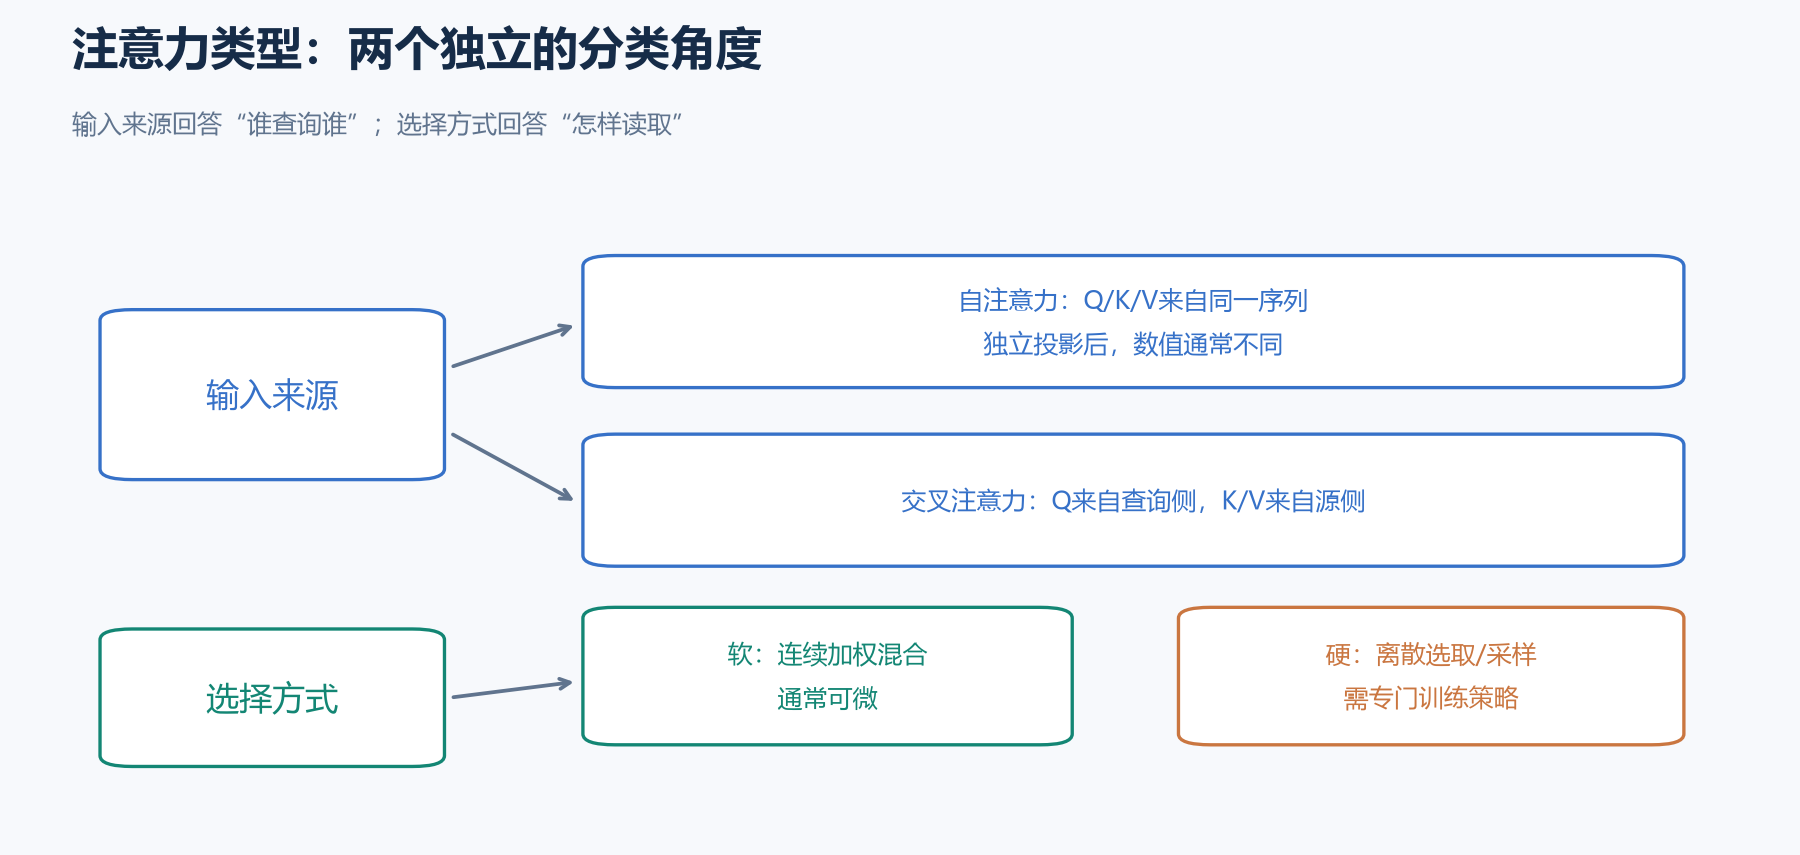

| 分类角度 | 类型 | 判断依据 |
| --- | --- | --- |
| 输入来源 | 自注意力 | Q、K、V由同一条序列的表示生成 |
| 输入来源 | 交叉注意力 | Q来自目标/查询侧，K/V来自另一条源/记忆序列 |
| 选择方式 | 软注意力 | 连续权重加权混合多个位置，常用Softmax，可微 |
| 选择方式 | 硬注意力 | 选取或采样离散位置，普通argmax路径不可直接微分 |

这两个分类角度可以组合：自注意力通常也可以是软注意力。课件用`Q==K==V`描述自注意力，是简化说法。实际常用$Q=XW_Q,K=XW_K,V=XW_V$，三个投影参数不同，**数值一般并不相等**；关键是它们来自同一个X。

硬注意力并不等于“Softmax里有一个权重比较大”。真正离散选择的训练需要专门估计策略，例如采样估计或松弛方法，不能直接把argmax当成可微算子。

```python
torch.manual_seed(SEED)
x = torch.randn(1, 4, 6, dtype=torch.float64)
wq = nn.Linear(6, 3, bias=False).double()
wk = nn.Linear(6, 3, bias=False).double()
wv = nn.Linear(6, 5, bias=False).double()
self_q, self_k, self_v = wq(x), wk(x), wv(x)
assert not torch.equal(self_q, self_k)
self_context, self_weights = scaled_dot_attention(self_q, self_k, self_v)
assert self_context.shape == (1, 4, 5)
print("同一X生成的Q/K数值不同，仍是自注意力")

soft_context, soft_weights = scaled_dot_attention(manual_q, manual_k, manual_v)
selected_positions = soft_weights.argmax(-1)
hard_context = torch.gather(manual_v, 1, selected_positions[..., None].expand(-1, -1, 2))
assert not torch.allclose(soft_context, hard_context)
print("软上下文:", soft_context, "离散选取上下文:", hard_context)
```

## 14. 位置顺序不是注意力公式自动提供的

没有位置特征、因果mask或其他顺序结构时，普通自注意力具有置换等变性：重排输入位置，输出也同样重排。对固定查询的交叉注意力，同时重排K、V对应行，汇总上下文不变。

```python
perm = torch.tensor([2, 0, 3, 1])
permuted_context, permuted_weights = scaled_dot_attention(wq(x[:, perm]), wk(x[:, perm]), wv(x[:, perm]))
torch.testing.assert_close(permuted_context, self_context[:, perm], atol=1e-10, rtol=1e-10)
torch.testing.assert_close(permuted_weights, self_weights[:, perm][:, :, perm], atol=1e-10, rtol=1e-10)
memory_perm = torch.tensor([2, 0, 1])
reordered_context, _ = scaled_dot_attention(manual_q, manual_k[:, memory_perm], manual_v[:, memory_perm])
torch.testing.assert_close(reordered_context, manual_context)
print("无位置特征的自注意力置换等变；K/V同步重排不改变固定查询的汇总")
```

这不是说词序不重要，而是词序必须通过位置编码、RNN状态或其他结构进入表示。打乱K却不打乱V会破坏匹配关系，不属于合法的同步重排。

## 15. 常见打分函数：点积、一般式、加性

对一个查询$q$与源位置键$k_j$：

| 规则 | 标量分数$e_j$ | 说明 |
| --- | --- | --- |
| 点积 | $q^\top k_j$ | Q/K维度相同，无额外打分参数 |
| 缩放点积 | $q^\top k_j/\sqrt{D_k}$ | 控制点积分数尺度 |
| 一般式/双线性 | $q^\top W k_j$ | W将两侧特征联系起来 |
| 加性注意力 | $v_a^\top\tanh(W_q q+W_k k_j+b)$ | 可允许Q/K特征维度不同 |

课件第29页还给出拼接线性式，以及`sum(tanh(Linear([Q,K])))`。后者可看作投影后用全1向量求和的一种特例；常见加性注意力再学习$v_a$，并对每个候选键分别打分。

注意：若对每个$q,k_j$直接做**无非线性的共享线性标量打分**，查询项会在Softmax中抵消：

$$e_j=w_q^\top q+w_k^\top k_j+b,\quad
\operatorname{softmax}_j(e_j)=\operatorname{softmax}_j(w_k^\top k_j).$$

这样的权重不随q变化。它与课件“把q和上一隐藏状态拼接，一次生成S个位置分数”的模块不是同一种计算结构。

```python
torch.manual_seed(SEED)
query_a = torch.randn(2, dtype=torch.float64)
query_b = query_a + torch.tensor([3., -2.], dtype=torch.float64)
keys = torch.randn(4, 3, dtype=torch.float64)
linear_pair_score = nn.Linear(5, 1).double()
def naive_linear_weights(query):
    pairs = torch.cat([query.expand(4, -1), keys], dim=-1)
    return linear_pair_score(pairs).squeeze(-1).softmax(-1)
torch.testing.assert_close(naive_linear_weights(query_a), naive_linear_weights(query_b))
print("无非线性共享线性逐键打分：改变query后权重不变")
```

选择打分规则要看模型与任务，不存在一个规则在所有数据上都最好。点积注意力也不天然等同于余弦相似度，它会受向量范数影响。

## 16. 可变源长度的加性注意力实现

下面对每个查询、每个源位置进行可学习打分。Q最后维可以与K不同，V又可使用不同维度。参数量不直接取决于源长度S，运行时S可以变化。

```python
class AdditiveAttention(nn.Module):
    def __init__(self, query_dim, key_dim, score_dim):
        super().__init__()
        self.query_proj = nn.Linear(query_dim, score_dim, bias=False)
        self.key_proj = nn.Linear(key_dim, score_dim, bias=True)
        self.score = nn.Linear(score_dim, 1, bias=False)

    def forward(self, q, k, v, allowed=None):
        if q.ndim != 3 or k.ndim != 3 or v.ndim != 3:
            raise ValueError("QKV必须为三维张量")
        if q.shape[0] != k.shape[0] or k.shape[:2] != v.shape[:2]:
            raise ValueError("batch或源长度不一致")
        projected_q = self.query_proj(q).unsqueeze(2)  # (B,L,1,A)
        projected_k = self.key_proj(k).unsqueeze(1)    # (B,1,S,A)
        pair_features = torch.tanh(projected_q + projected_k)
        scores = self.score(pair_features).squeeze(-1)  # (B,L,S)
        weights = masked_softmax(scores, allowed)
        return torch.bmm(weights, v), weights

torch.manual_seed(SEED)
additive = AdditiveAttention(4, 6, 8).double()
aq = torch.randn(2, 3, 4, dtype=torch.float64)
ak = torch.randn(2, 5, 6, dtype=torch.float64)
av = torch.randn(2, 5, 7, dtype=torch.float64)
add_context, add_weights = additive(aq, ak, av, batch_allowed)
assert add_context.shape == (2, 3, 7) and add_weights.shape == (2, 3, 5)
assert torch.all(add_weights[~batch_allowed] == 0)
torch.testing.assert_close(add_weights.sum(-1), torch.ones((2, 3), dtype=torch.float64))
for index, length in enumerate(source_lengths.tolist()):
    unpadded, _ = additive(aq[index:index+1], ak[index:index+1, :length], av[index:index+1, :length])
    torch.testing.assert_close(unpadded[0], add_context[index])
other_context, other_weights = additive(aq + 2.0, ak, av, batch_allowed)
assert (other_weights - add_weights).abs().max().item() > 1e-6
print("加性上下文", tuple(add_context.shape), "改变query后的权重差", (other_weights-add_weights).abs().max().item())
```

本例把广播仅用于明确的`L×S`成对打分，batch维仍严格匹配。加性注意力的中间`(B,L,S,A)`可能较大，实际实现应考虑内存与任务规模。

## 17. 读懂课件MyAtt：固定位置打分模块

课件第31–33页使用Q=`(1,1,32)`、K=`(1,1,32)`、V=`(1,10,32)`。这里的K是**一个状态向量**，不是10个源位置的键向量；`Linear(32+32,10)`一次生成10个位置分数。

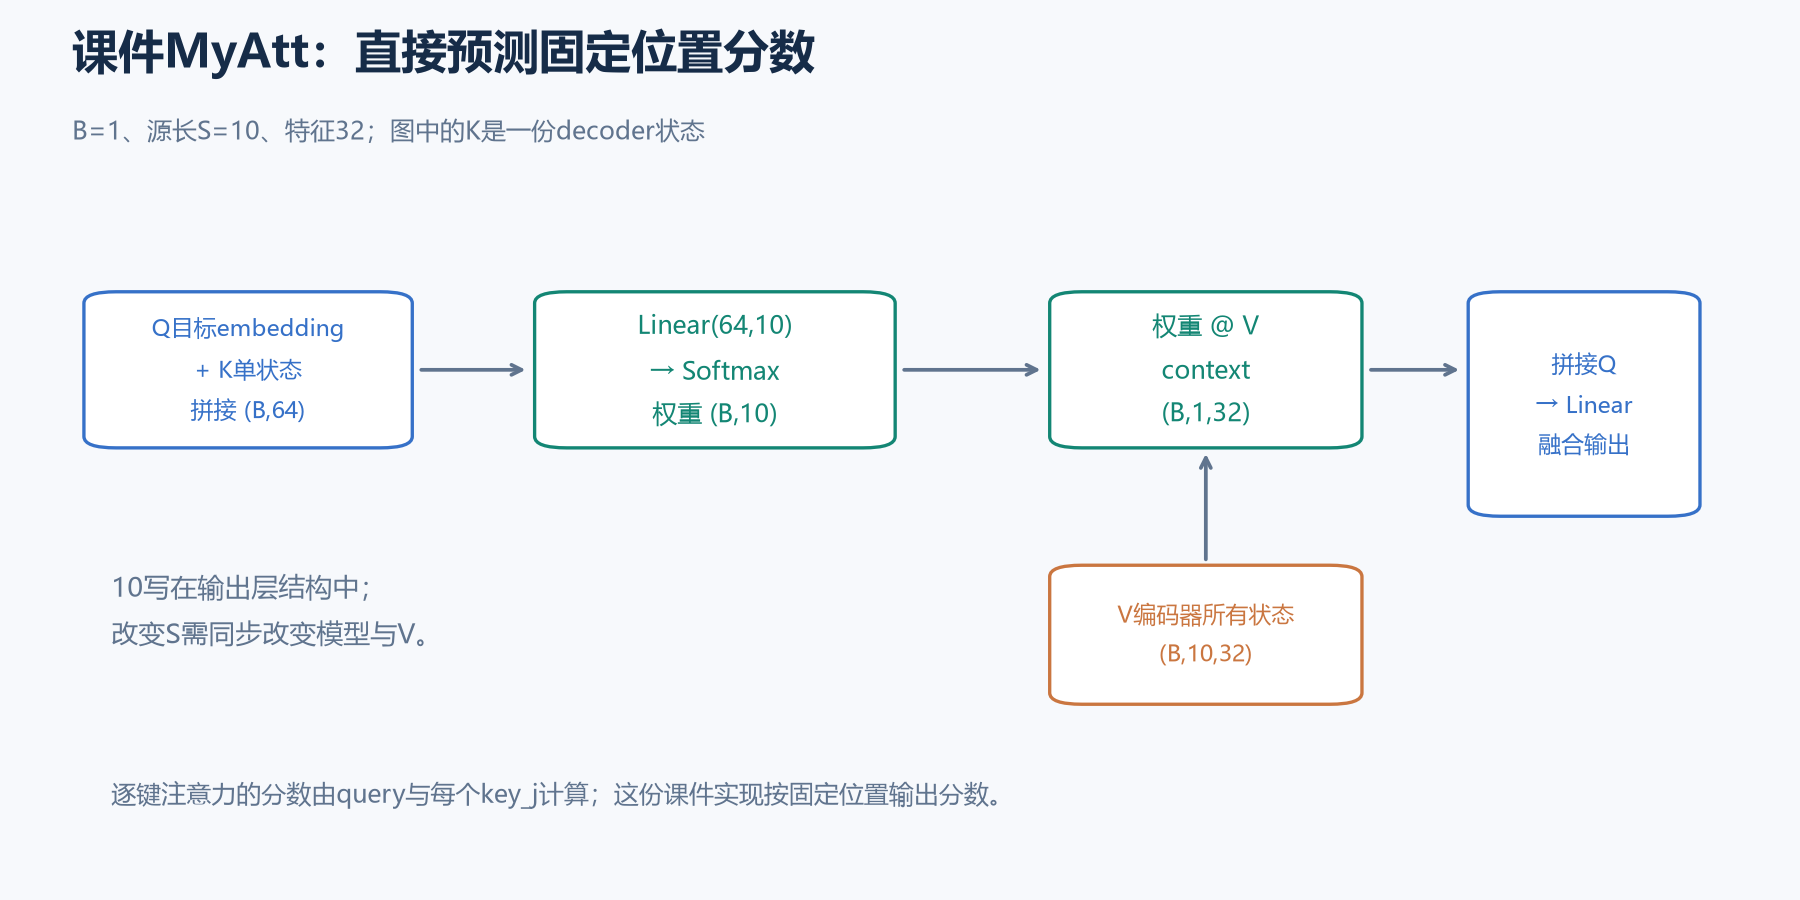

| 步骤 | 运算 | batch=1时shape |
| --- | --- | --- |
| 拼接查询与状态 | `cat(Q[0], K[0])` | `(1,64)` |
| 预测位置分数 | `Linear(64,10)` | `(1,10)` |
| 归一化 | `Softmax(-1)` | `(1,10)` |
| 读取内容 | 权重乘V | `(1,1,32)` |
| 融合 | `cat(Q, context)` | `(1,64)` |
| 输出投影 | `Linear(64,32)` | `(1,1,32)` |

课件部分注释把权重写成`(1,32)`，实际应是`(1,10)`。权重长度等于**源位置数**，不是隐藏特征数。

这种早期教学设计可以使用，但有明确限制：S固定在输出层大小里；权重由query与state生成，不直接比较每个源位置的内容键。换成20个位置，必须重建该位置输出层并重新训练相应参数。

## 18. 固定位置模块的批量实现与原式对照

本篇把接口整理成`q/state=(B,D)`、`values=(B,S,Dv)`。context计算用`weights.unsqueeze(1)`，得到`(B,1,S)`。课件的`unsqueeze(0)`在B=1时碰巧一样，B>1时变成`(1,B,S)`，不再是bmm所需的batch结构。

```python
class FixedPositionAttention(nn.Module):
    def __init__(self, query_dim, state_dim, source_slots, value_dim, output_dim):
        super().__init__()
        self.source_slots = source_slots
        self.attn = nn.Linear(query_dim + state_dim, source_slots)
        self.combine = nn.Linear(query_dim + value_dim, output_dim)

    def forward(self, q, state, values, key_valid=None):
        if q.ndim != 2 or state.ndim != 2 or values.ndim != 3:
            raise ValueError("q/state应为(B,D)，values应为(B,S,Dv)")
        if q.shape[0] != state.shape[0] or q.shape[0] != values.shape[0]:
            raise ValueError("batch大小不一致")
        if values.shape[1] != self.source_slots:
            raise ValueError("源长度与固定输出位置数不一致")
        scores = self.attn(torch.cat([q, state], dim=-1)).unsqueeze(1)
        allowed = None if key_valid is None else key_valid[:, None, :]
        weights = masked_softmax(scores, allowed).squeeze(1)
        context = torch.bmm(weights.unsqueeze(1), values).squeeze(1)
        output = self.combine(torch.cat([q, context], dim=-1))
        return output.unsqueeze(1), weights

torch.manual_seed(SEED)
fixed_att = FixedPositionAttention(32, 32, 10, 32, 32).double()
course_q = torch.randn(1, 1, 32, dtype=torch.float64)
course_state = torch.randn(1, 1, 32, dtype=torch.float64)
course_v = torch.randn(1, 10, 32, dtype=torch.float64)
fixed_output, fixed_weights = fixed_att(course_q[0], course_state[0], course_v)
original_weights = fixed_att.attn(torch.cat([course_q[0], course_state[0]], -1)).softmax(-1)
original_context = torch.bmm(original_weights.unsqueeze(0), course_v)
original_output = fixed_att.combine(torch.cat([course_q[0], original_context[0]], -1)).unsqueeze(0)
torch.testing.assert_close(fixed_weights, original_weights)
torch.testing.assert_close(fixed_output, original_output)
assert fixed_output.shape == (1, 1, 32) and fixed_weights.shape == (1, 10)

fq = torch.randn(2, 32, dtype=torch.float64)
fs = torch.randn(2, 32, dtype=torch.float64)
fv = torch.randn(2, 10, 32, dtype=torch.float64)
fvalid = torch.arange(10)[None, :] < torch.tensor([7, 10])[:, None]
fo, fw = fixed_att(fq, fs, fv, fvalid)
assert fo.shape == (2, 1, 32) and fw.shape == (2, 10)
assert torch.all(fw[~fvalid] == 0)
assert sum(p.numel() for p in fixed_att.parameters()) == 2730
print("课件batch=1代数一致；批量版output", tuple(fo.shape), "weights", tuple(fw.shape))
```

原例中的第一个维度可理解为单时间步/单层状态，后续代码不能随意用`Q[0]`丢掉一个真实batch维。接口从`(1,B,D)`换成`(B,D)`时要明确转换，不能凭维数猜测。

## 19. 固定位置打分与逐键打分有什么区别

固定位置模块的10个输出单元分别学第1–10位置的打分方式。它可以训练，但本身不读取每个候选的内容键。逐键加性/点积注意力则对每个`(query,key_j)`计算分数，同一套打分参数可用于不同源长度。

```python
# 固定位置模块：只改变values，权重不变，内容汇总会变。
changed_fo, changed_fw = fixed_att(fq, fs, fv + 3.0, fvalid)
torch.testing.assert_close(changed_fw, fw)
assert not torch.allclose(changed_fo, fo)
try:
    fixed_att(fq, fs, torch.randn(2, 20, 32, dtype=torch.float64))
except ValueError:
    print("固定位置层已拒绝20位置输入：需要同步改变模型配置")
else:
    raise AssertionError("固定位置模型不能自动改变源长度")

# 同一逐键加性模块，不重建参数就能读取20个源位置。
long_k = torch.randn(2, 20, 6, dtype=torch.float64)
long_v = torch.randn(2, 20, 7, dtype=torch.float64)
long_context, long_weights = additive(aq, long_k, long_v)
assert long_context.shape == (2, 3, 7) and long_weights.shape == (2, 3, 20)
print("逐键加性注意力支持新的源长度：", tuple(long_weights.shape))
```

这里比较的是**这两个具体实现**，不能把课件所有“拼接+Linear”表达式都视为相同结构。逐键拼接打分若只是共享线性标量层，存在第15节的query项抵消；课件`Linear(64,10)`输出10个不同位置的分数，并不是那个逐键共享标量公式。

## 20. Seq2Seq：输入与输出长度可以不同

Seq2Seq把一个序列映射成另一个序列，例如机器翻译、摘要或语音转写。源长度S、目标长度T一般不相等，也不要求每个源词对应一个目标词。

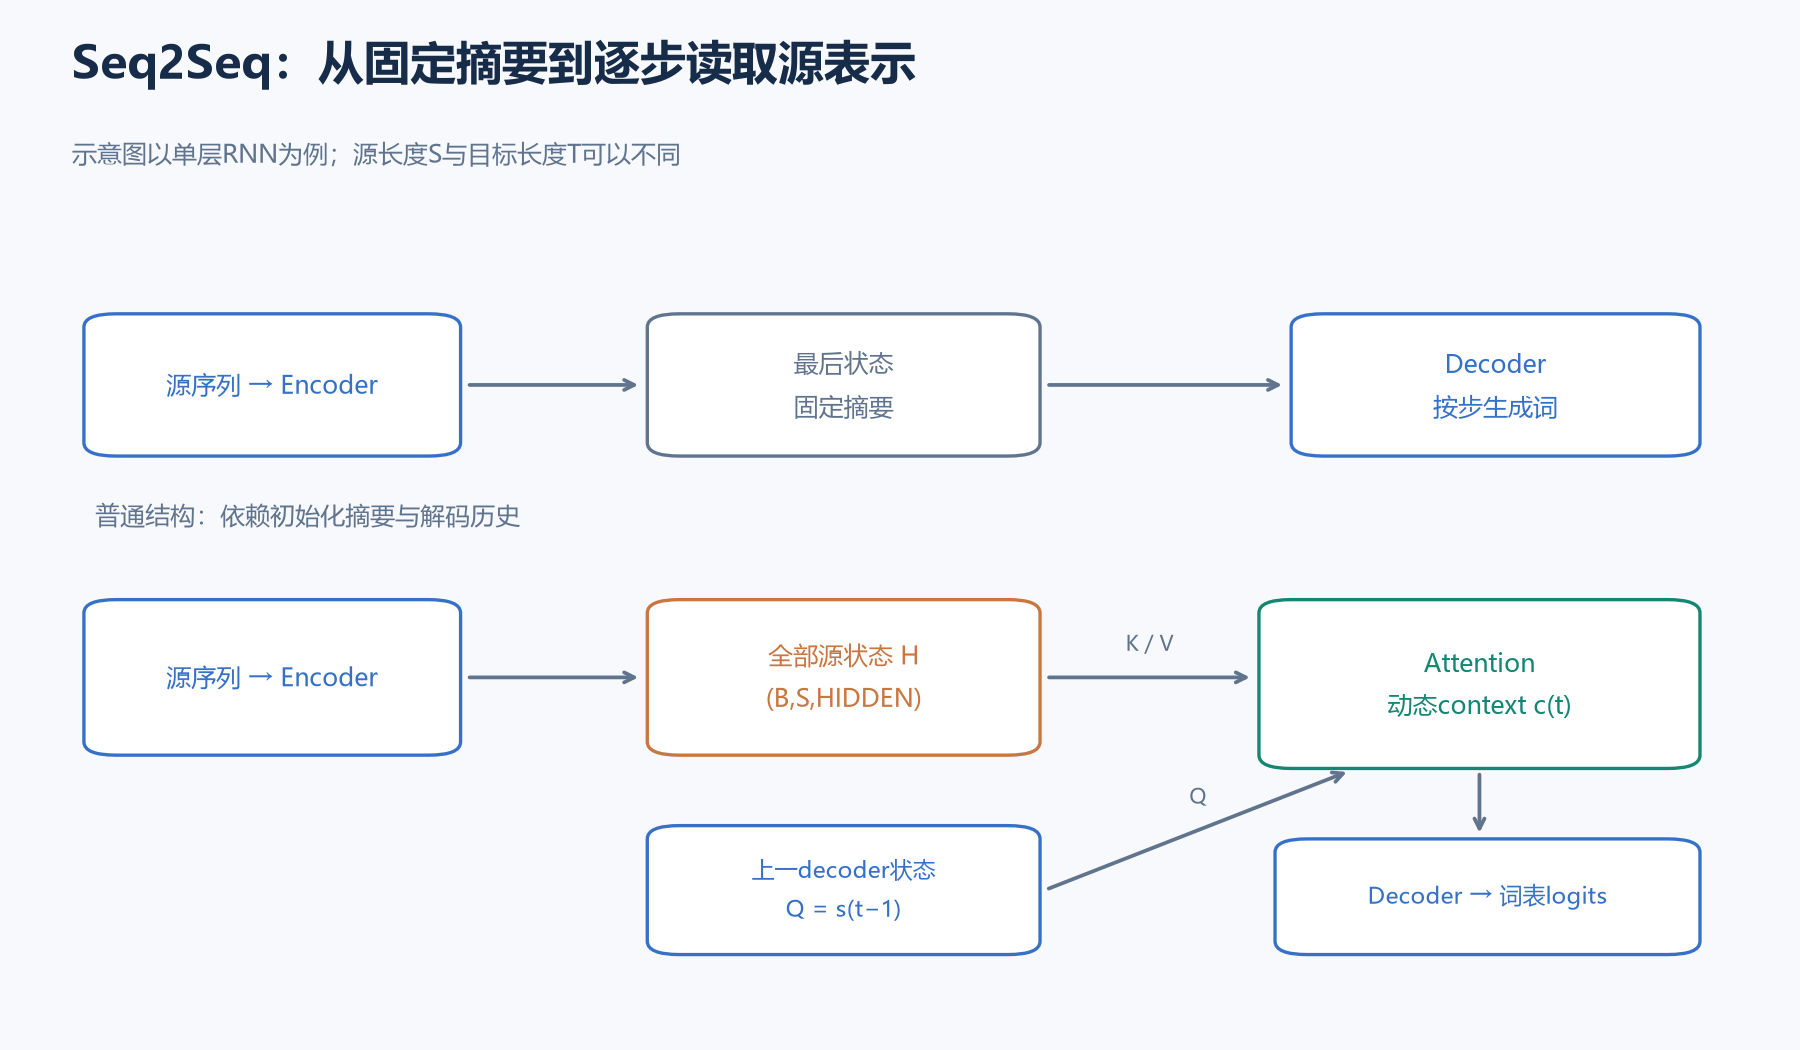

普通Encoder–Decoder通常用编码器最后状态初始化解码器。解码器按步生成，模型仍能保留解码历史，但不能在每一步重新直接读取所有源端位置；带注意力结构额外保留编码器输出`H=(h_1,…,h_S)`，在每个解码步得到新的上下文`c_t`。

一种常见的带注意力RNN解码流程是：

$$e_{t,j}=v_a^\top\tanh(W_qs_{t-1}+W_kh_j+b),\quad
\alpha_{t,:}=\operatorname{softmax}(e_{t,:}),\quad
c_t=\sum_{j=1}^{S}\alpha_{t,j}h_j.$$

$$s_t=\operatorname{GRU}([\operatorname{Emb}(y_{t-1});c_t],s_{t-1}),\quad
\ell_t=W_o[s_t;c_t]+b_o.$$

`ℓ_t`是目标词表上的logits，不是源端注意力权重。源端Softmax有S个位置；词预测Softmax有目标词表大小`V_target`个类别。两者轴与用途不同。

## 21. QKV的来源要结合具体实现

课件第19–22页把Q称为当前目标embedding、K称为上一步解码器隐藏状态、V称为所有编码器输出；它与第31页固定位置层相配套。本篇后面的逐键加性实现采用另一种常见约定：

| 内容 | 课件固定位置设计 | 本篇单步Seq2Seq实现 |
| --- | --- | --- |
| 查询信息 | 目标词embedding | 上一步decoder hidden |
| 分数的另一输入 | 一个decoder状态向量 | 每个源位置的encoder hidden |
| 被汇总内容 | 所有encoder输出 | 所有encoder输出 |
| 源长度 | 固定位置输出层指定 | 由memory的S维决定 |

本篇因此令`Q=s_(t-1)`、`K=H`、`V=H`，再把上一个目标词embedding与context一起输入decoder。两种接口都能讲清各自计算，但不能把课件单一K状态直接塞进要求S个内容键的公式。

若encoder与decoder隐藏维度不同，需要用于状态初始化的桥接投影；双向或多层encoder也应显式处理方向与层数。本篇用单层、单向、同隐藏维度，先验证基本接口。

## 22. 可运行：源端编码与一个带注意力解码步

源端采用右PAD，真实长度分别为3与5；packing避免GRU把PAD继续读入最终状态。`memory`保留每个源位置，`encoder_h[-1]`初始化单层decoder。第一个decoder输入是SOS，不是第一个要预测的目标词。

```python
torch.manual_seed(SEED)
PAD_ID, SOS_ID = 0, 1
src_ids = torch.tensor([[3, 4, 5, 0, 0], [6, 7, 8, 9, 10]])
src_lengths = torch.tensor([3, 5], dtype=torch.long)  # packing的lengths放CPU
B, S = src_ids.shape
HIDDEN, EMBED, TARGET_VOCAB = 12, 8, 13
src_embed = nn.Embedding(16, EMBED, padding_idx=PAD_ID)
encoder = nn.GRU(EMBED, HIDDEN, batch_first=True)
tgt_embed = nn.Embedding(TARGET_VOCAB, EMBED, padding_idx=PAD_ID)
seq_attention = AdditiveAttention(HIDDEN, HIDDEN, 10)
decoder = nn.GRU(EMBED + HIDDEN, HIDDEN, batch_first=True)
token_head = nn.Linear(2 * HIDDEN, TARGET_VOCAB)

packed = pack_padded_sequence(src_embed(src_ids), src_lengths,
                             batch_first=True, enforce_sorted=False)
packed_memory, encoder_h = encoder(packed)
memory, restored_lengths = pad_packed_sequence(
    packed_memory, batch_first=True, total_length=S)
assert memory.shape == (B, S, HIDDEN) and encoder_h.shape == (1, B, HIDDEN)
torch.testing.assert_close(restored_lengths, src_lengths)

source_valid = torch.arange(S)[None, :] < src_lengths[:, None]
prev_hidden = encoder_h[-1]                   # (B,HIDDEN)
query = prev_hidden[:, None, :]              # (B,1,HIDDEN)
context, src_weights = seq_attention(
    query, memory, memory, source_valid[:, None, :])
previous_tokens = torch.full((B, 1), SOS_ID, dtype=torch.long)
decoder_input = torch.cat([tgt_embed(previous_tokens), context], dim=-1)
decoder_out, next_hidden = decoder(decoder_input, encoder_h)
token_logits = token_head(torch.cat([decoder_out, context], dim=-1))

assert src_weights.shape == (B, 1, S)
assert context.shape == (B, 1, HIDDEN)
assert next_hidden.shape == (1, B, HIDDEN)
assert token_logits.shape == (B, 1, TARGET_VOCAB)
assert torch.all(src_weights[:, 0][~source_valid] == 0)
torch.testing.assert_close(src_weights.sum(-1), torch.ones(B, 1))
assert torch.isfinite(token_logits).all()
print("memory", tuple(memory.shape), "源权重", tuple(src_weights.shape))
print("context", tuple(context.shape), "词表logits", tuple(token_logits.shape))

# 自编目标只用于验证反向链路，并非课程翻译样本。
toy_next_tokens = torch.tensor([4, 6])
step_loss = F.cross_entropy(token_logits[:, 0], toy_next_tokens)
step_loss.backward()
for name, module in (("encoder", encoder), ("attention", seq_attention),
                     ("decoder", decoder), ("token_head", token_head)):
    gradients = [p.grad for p in module.parameters() if p.requires_grad]
    assert all(g is not None and torch.isfinite(g).all() for g in gradients)
    assert sum(g.abs().sum().item() for g in gradients) > 0
    print(name, "收到有限且非零的梯度")
seq_step_loss = step_loss.item()
print("单步示例loss:", seq_step_loss)
```

这段代码验证张量接口、PAD处理和反向传播，没有训练翻译器。随机logits的argmax只是随机模型预测，不能解释为已学会翻译。

## 23. 训练与生成：teacher forcing、EOS与损失

若真实目标是`[词A, 词B, EOS]`，训练时decoder输入通常是`[SOS, 词A, 词B]`，预测目标是`[词A, 词B, EOS]`。这种使用前一真实词的方式称为teacher forcing。

推理时没有真实目标，使用上一轮模型生成的词，直到EOS或长度上限。训练与生成的输入分布因此可能不同；看到teacher forcing损失下降，不等于自由生成就完全正确。

对于完整batch，词预测logits常为`(B,T,V_target)`，目标索引为`(B,T)`，可用：

```python
# 仅演示目标PAD如何从词预测损失中排除。
torch.manual_seed(SEED)
toy_sequence_logits = torch.randn(2, 3, TARGET_VOCAB)
toy_targets = torch.tensor([[4, 6, 2], [5, 2, PAD_ID]])
loss_all = F.cross_entropy(toy_sequence_logits.reshape(-1, TARGET_VOCAB),
                           toy_targets.reshape(-1), ignore_index=PAD_ID)
used = toy_targets != PAD_ID
loss_selected = F.cross_entropy(toy_sequence_logits[used], toy_targets[used])
torch.testing.assert_close(loss_all, loss_selected)
print("ignore_index损失与显式排除PAD一致:", loss_all.item())
```

训练时将**未Softmax的logits**交给CrossEntropyLoss；源端注意力权重则在读取V前已经Softmax。源端mask处理“读哪里”，目标端`ignore_index`处理“哪些预测参与损失”，二者需要分别实现。

## 24. 微型学习实验：训练注意力读取指定向量

手算检验公式；下面再验证参数确实可以通过注意力链路学习。构造3个查询和3个候选键，用单位基向量标识；候选内容是三个二维向量。任务是查询0/1/2分别读出第0/1/2个候选内容。

仅训练Q、K的线性投影，V固定，不设置可以绕过检索的下游分类器。损失是上下文与目标向量的MSE；3个候选是三角形顶点，读准目标顶点要求权重集中到相应位置。

```python
class TinyRetriever(nn.Module):
    def __init__(self):
        super().__init__()
        self.q_proj = nn.Linear(3, 8, bias=False)
        self.k_proj = nn.Linear(3, 8, bias=False)

    def forward(self, query_features, key_features, values):
        return scaled_dot_attention(self.q_proj(query_features),
                                    self.k_proj(key_features), values)

torch.manual_seed(SEED)
retriever = TinyRetriever()
query_features = torch.eye(3)[:, None, :]             # (3,1,3)
key_features = torch.eye(3)[None, :, :].expand(3, -1, -1)
candidate_values = torch.tensor([[2., 0.], [0., 2.], [-2., -2.]])
retrieval_values = candidate_values[None, :, :].expand(3, -1, -1)
retrieval_targets = candidate_values[:, None, :]      # (3,1,2)
optimizer = torch.optim.Adam(retriever.parameters(), lr=0.05)
before_parameters = [p.detach().clone() for p in retriever.parameters()]

with torch.no_grad():
    initial_read, initial_retrieval_weights = retriever(
        query_features, key_features, retrieval_values)
    initial_retrieval_loss = F.mse_loss(initial_read, retrieval_targets).item()

retrieval_history = [initial_retrieval_loss]
first_gradient_norm = None
for training_step in range(180):
    optimizer.zero_grad(set_to_none=True)
    read, weights = retriever(query_features, key_features, retrieval_values)
    retrieval_loss = F.mse_loss(read, retrieval_targets)
    retrieval_loss.backward()
    grads = [p.grad for p in retriever.parameters()]
    assert all(g is not None and torch.isfinite(g).all() for g in grads)
    if training_step == 0:
        first_gradient_norm = math.sqrt(sum(g.square().sum().item() for g in grads))
        assert first_gradient_norm > 0
    optimizer.step()
    with torch.no_grad():
        post_read, _ = retriever(query_features, key_features, retrieval_values)
        retrieval_history.append(F.mse_loss(post_read, retrieval_targets).item())

with torch.no_grad():
    final_read, final_retrieval_weights = retriever(
        query_features, key_features, retrieval_values)
    final_retrieval_loss = F.mse_loss(final_read, retrieval_targets).item()
    selected_keys = final_retrieval_weights[:, 0].argmax(-1)
assert final_retrieval_loss < initial_retrieval_loss * 0.05
assert torch.equal(selected_keys, torch.arange(3))
assert all(not torch.equal(old, new) for old, new in zip(before_parameters, retriever.parameters()))
assert all(math.isfinite(value) for value in retrieval_history)
torch.testing.assert_close(final_retrieval_weights.sum(-1), torch.ones(3, 1))
print("初始MSE:", initial_retrieval_loss, "最终MSE:", final_retrieval_loss)
print("首次梯度范数:", first_gradient_norm)
print("读取位置:", selected_keys.tolist())
print("最终注意力:\n", final_retrieval_weights[:, 0])
print("最终上下文:\n", final_read[:, 0])
```

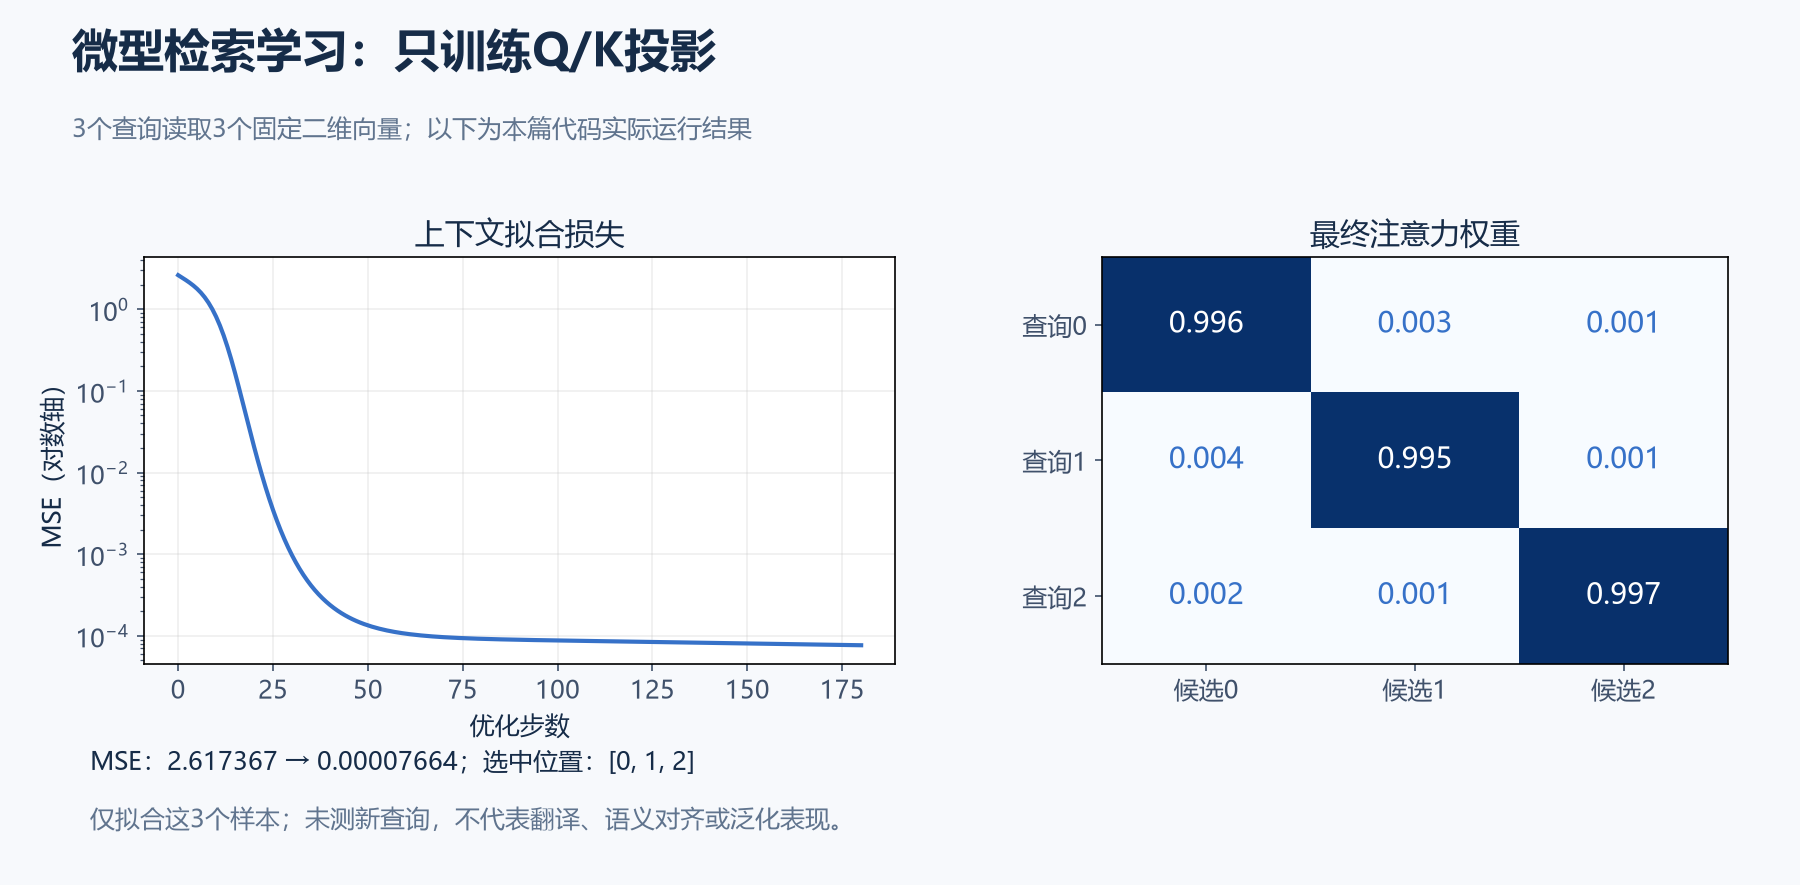

实验只有3个训练样本，验证的是**可学习检索与梯度链路**，没有测试新查询，不证明语言对齐、翻译质量或泛化能力。学习曲线和热力图来自本篇代码实际运行，具体结果见后面的验证记录。

## 25. 常见错误与排查顺序

| 现象/写法 | 原因 | 处理 |
| --- | --- | --- |
| 权重沿特征维归一化 | 混淆Dk与S | 检查scores为`(B,L,S)`，沿S做Softmax |
| `bmm`报batch不一致 | `unsqueeze`放错轴或丢掉batch | 核对`(B,L,S) @ (B,S,Dv)` |
| PAD占正权重 | 只把embedding置零 | 在Softmax前屏蔽分数 |
| 权重/上下文出现NaN | 全屏蔽或上游非有限值 | 先确认至少一个有效key，再检查分数与输入 |
| 把点积分数叫权重 | 未归一化 | scores可以为负；weights非负且每行和为1 |
| 修改源长度后课件Linear报错 | 固定位置数写入层结构 | 同步更改层配置与V，或用逐键打分 |
| Softmax后再乘mask | 权重总和变小，输出缩放变化 | 归一化前屏蔽，或谨慎重归一化 |
| `torch.sqrt(shape[-1])` | 输入是Python int | 使用`math.sqrt(Dk)` |
| 自注意力必须Q/K/V数值相等 | 忽略独立投影 | 按同一输入来源判断 |
| 权重图“证明模型理解” | 将可视化当作因果解释 | 结合任务评估、干预与限制解释 |

调试顺序：先检查shape和dtype/device，再检查mask有效行，再检查Softmax轴和行和，最后核对上下文、梯度与任务损失。随机初始化结果只说明运算可执行。

## 26. 课件核对与实现注记

| 课件位置 | 本篇处理 |
| --- | --- |
| 第18–22页：Seq2Seq与QKV来源 | 保留课程约定，同时说明本篇逐键模型的接口差异 |
| 第29页：多种打分规则 | 给出点积、缩放、双线性与加性；补充无非线性共享拼接标量的query抵消问题 |
| 第31–33页：MyAtt与测试 | 将权重shape纠正为`(1,10)`，并提供batch>1的实现 |
| 第34–35页：自注意力 | 将“Q=K=V”解释为简化例子，实际依据输入来源 |
| 第37页：长度20练习 | 模型位置数与V的S维必须同步；部分示例仍用10，不能只改一处 |
| 第38页：缩放作用 | 解释分数方差与Softmax饱和，避免把缩放视为万能梯度解法 |
| 第39页：计算题 | B为点积分数，C经Softmax才是权重；修正对Python整数调用torch.sqrt |

本篇加入padding、causal、内置函数对照和微型训练，是为验证计算边界而做的补充；这些补充不是对课件视频内容的逐字转述。

## 27. 练习与参考答案

1. **Q=`(2,3,4)`、K=`(2,5,4)`、V=`(2,5,7)`，输出是什么shape？** 分数/权重为`(2,3,5)`，上下文为`(2,3,7)`；缩放分母为`sqrt(4)=2`。
2. **一行分数全部加同一常数，权重变吗？** 不变。Softmax具有平移不变性，这也解释了第15节共享线性query项为何抵消。
3. **padding K/V置零为什么仍需mask？** 零分数的指数不是零，PAD仍会占据归一化质量。
4. **所有位置都被mask时怎么办？** 先修复长度或有效位置逻辑；本篇直接报错。产品实现若定义特殊输出，必须显式规定并单独测试。
5. **点积与加性注意力的Q/K必须同维吗？** 普通点积必须同维；加性可先分别投影到共同打分维度，不要求原始Dq=Dk。
6. **K与V为什么不能各自独立乱序？** 同一列权重必须乘与该key对应的value；同步重排K/V保持对应关系，单独重排会读错内容。
7. **源注意力的Softmax与词预测的Softmax有什么区别？** 前者分布在源位置上以汇总V，后者分布在目标词表上以预测token。
8. **换成20个源位置，课件MyAtt和逐键模块分别怎样改？** MyAtt的固定输出位置数与V要同步修改；逐键模块参数可以复用，但新mask和输入S维仍须匹配。
9. **自注意力不带位置信息能知道词序吗？** 单靠普通无mask内容注意力不能确定位置顺序；需要位置特征、RNN状态、因果结构等信息。
10. **本篇训练实验可以证明什么？** 可以证明Q/K投影经注意力与MSE得到梯度，并拟合3个检索样本；不能证明语言理解或对新数据的性能。

## 28. 实际验证记录

验证日期：2026-10-13。Python 3.12.13、NumPy 1.26.4、PyTorch 2.14.1+cpu，CPU，随机种子2026。

| 验证项 | 实际结果 |
| --- | --- |
| 按顺序运行Python代码块 | 18段全部通过，无需下载数据 |
| bmm与逐batch/NumPy手算 | 在浮点容差内一致 |
| mask | PAD权重为0、行和为1、全屏蔽行被拒绝 |
| padding/causal不变量 | 改PAD内容不改变输出；改未来位置不影响前三输出 |
| PyTorch内置SDPA对照 | 最大绝对误差 `5.551e-16` |
| 自注意力置换与K/V同步重排 | 满足代码中的等变/不变检查 |
| 课件固定位置模块 | B=1原式一致；B=2与右PAD可运行；参数2730个 |
| 逐键加性注意力 | B=2、L=3、Dq/Dk/Dv不同、S从5变20均通过 |
| Seq2Seq单步 | memory/权重/context/logits形状通过；4个模块收到有限非零梯度；示例CE `2.386982` |
| 目标PAD损失 | ignore_index与显式筛选结果一致 |
| 微型检索训练180步 | MSE `2.617367` → `0.00007664`，3个查询均选中目标位置 |
| 首次训练梯度 | 范数 `0.595542`，参数确实更新 |
| 文件结构 | 全部Markdown cells，7幅PNG以attachments内嵌，无外部图片依赖 |
| 既有笔记 | 54本SHA256校验一致 |


代码块共享一个运行环境按顺序执行，图中的手算和学习曲线使用同一次运行产生的数值。不同PyTorch版本的数值可能存在小差异，应以不变量、容差与损失趋势为主。

## 29. 资料索引与复习路径

主资料：[NLP百度网盘课程](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码`1234`。对应`03-视频/day05`的14节与`01-课件/06-注意力机制介绍.pdf`，39页。

API参考：[torch.bmm](https://docs.pytorch.org/docs/stable/generated/torch.bmm.html)、[scaled_dot_product_attention](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html)、[GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html)、[pack_padded_sequence](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html)、[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)。API链接用于进一步查阅，不表示本篇逐页核对了各版本文档。

复习时先独立写出`(B,L,Dk) → (B,L,S) → (B,L,Dv)`，再跑手算、mask与bmm样例，最后读课件固定位置模块和Seq2Seq单步。能够说清“当前查询、源位置分布、上下文、目标词logits”四者的区别，就掌握了本日计算主线。